# CORDIC Algorithm Exploration

This notebook walks through the **CORDIC (COordinate Rotation DIgital Computer)** algorithm step by step, building intuition for how it works and visualizing each micro-rotation.

We'll cover:
1. **Core Idea** — Successive micro-rotations using only shift-and-add
2. **Circular Mode** — Computing sin/cos via rotation mode
3. **Convergence & Precision** — How iteration count affects accuracy
4. **Fixed-Point Behavior** — Emulating the RTL's integer arithmetic
5. **Hyperbolic Mode** — Computing square roots via vectoring mode

In [2]:
import math
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    'figure.figsize': (10, 6),
    'axes.grid': True,
    'font.size': 11,
    'axes.facecolor': '#1a1a2e',
    'figure.facecolor': '#16213e',
    'axes.edgecolor': '#e94560',
    'axes.labelcolor': '#eaeaea',
    'xtick.color': '#eaeaea',
    'ytick.color': '#eaeaea',
    'text.color': '#eaeaea',
    'grid.color': '#2a2a4a',
    'grid.alpha': 0.5,
})

---
## 1. The Core CORDIC Engine

The fundamental insight: rotating a 2D vector by an angle $\alpha_j = \arctan(2^{-j})$ simplifies the trigonometric multiplication into a **bit-shift** and an **add/subtract**:

$$
\begin{bmatrix} x_{j+1} \\ y_{j+1} \end{bmatrix}
= \begin{bmatrix} x_j - \sigma_j \cdot y_j \cdot 2^{-j} \\ y_j + \sigma_j \cdot x_j \cdot 2^{-j} \end{bmatrix}
$$

where $\sigma_j = \pm 1$ decides the rotation direction.

Let's implement this and trace the vector path.

In [3]:
def cordic_circular_rotation(x0, y0, z0, n_iter, trace=False):
    """
    Circular CORDIC — Rotation Mode.
    Drives z (remaining angle) toward 0.
    
    Returns: (x_final, y_final, z_final, [optional trace])
    """
    # Pre-compute the atan look-up table
    atan_lut = [math.atan(2**-j) for j in range(n_iter)]
    
    x, y, z = x0, y0, z0
    history = [(x, y, z)] if trace else None
    
    for j in range(n_iter):
        # Decision: rotate CW or CCW based on sign of remaining angle
        sigma = 1 if z >= 0 else -1
        
        # Micro-rotation (shift-and-add)
        x_next = x - sigma * (2**-j) * y
        y_next = y + sigma * (2**-j) * x
        z_next = z - sigma * atan_lut[j]
        
        x, y, z = x_next, y_next, z_next
        if trace:
            history.append((x, y, z))
    
    return (x, y, z, history) if trace else (x, y, z)


def get_cordic_gain(n_iter):
    """Compute the CORDIC scaling factor K for circular mode."""
    K = 1.0
    for j in range(n_iter):
        K *= math.sqrt(1 + 2**(-2*j))
    return K


# Quick sanity check
N = 16
K = get_cordic_gain(N)
print(f'CORDIC gain K({N} iterations) = {K:.6f}')
print(f'1/K = {1/K:.6f}')
print(f'\nTo get cos/sin directly, set x0 = 1/K = {1/K:.6f}')

CORDIC gain K(16 iterations) = 1.646760
1/K = 0.607253

To get cos/sin directly, set x0 = 1/K = 0.607253


---
## 2. Visualizing the Micro-Rotations

Let's trace the CORDIC vector as it "zigzags" toward the target angle. Each arrow is one micro-rotation. The angle steps get smaller with each iteration — the first few rotations do the coarse steering, the later ones fine-tune.

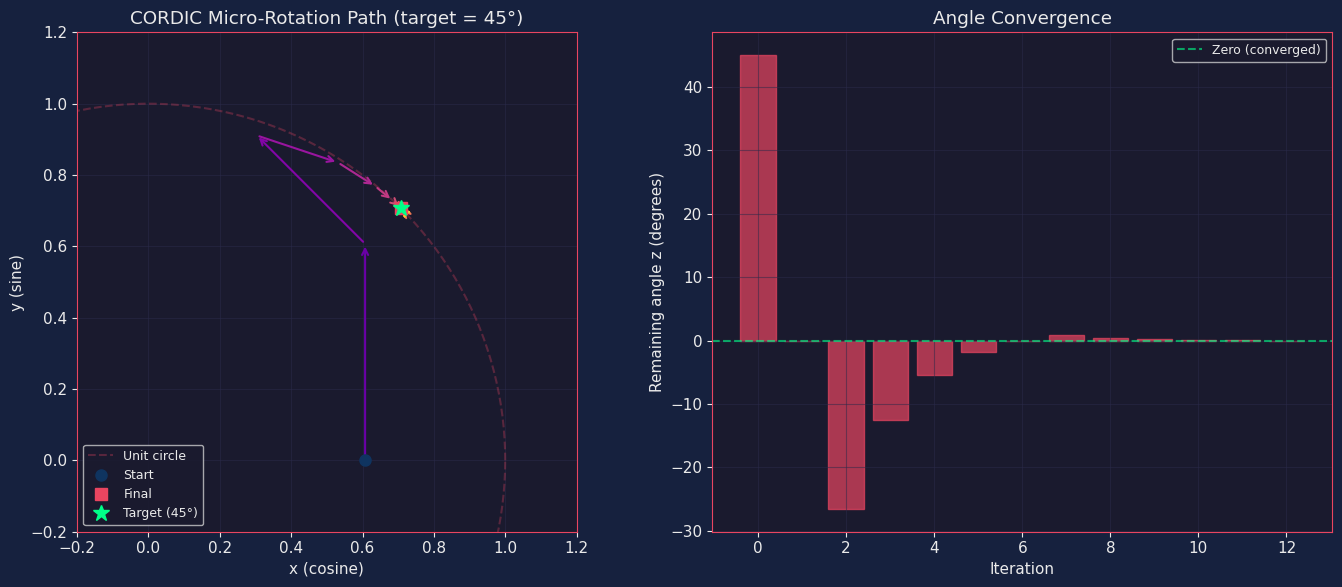


Result: cos(45°) = 0.706988 (exact: 0.707107)
Result: sin(45°) = 0.707226 (exact: 0.707107)
Remaining angle z = -0.00963236°


In [4]:
target_angle = math.radians(45)  # Try changing this!
N = 12
K = get_cordic_gain(N)

x0, y0, z0 = 1/K, 0.0, target_angle
x_f, y_f, z_f, history = cordic_circular_rotation(x0, y0, z0, N, trace=True)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# --- Left: Vector path on the unit circle ---
theta_circle = np.linspace(0, 2*np.pi, 200)
ax1.plot(np.cos(theta_circle), np.sin(theta_circle), '--', color='#e94560', alpha=0.3, label='Unit circle')

xs = [h[0] for h in history]
ys = [h[1] for h in history]
colors = plt.cm.plasma(np.linspace(0.2, 0.9, len(xs)-1))

for i in range(len(xs)-1):
    ax1.annotate('', xy=(xs[i+1], ys[i+1]), xytext=(xs[i], ys[i]),
                arrowprops=dict(arrowstyle='->', color=colors[i], lw=1.5))

ax1.plot(xs[0], ys[0], 'o', color='#0f3460', markersize=8, label='Start', zorder=5)
ax1.plot(xs[-1], ys[-1], 's', color='#e94560', markersize=8, label='Final', zorder=5)
ax1.plot(math.cos(target_angle), math.sin(target_angle), '*', color='#00ff88',
         markersize=12, label=f'Target ({math.degrees(target_angle):.0f}°)', zorder=5)

ax1.set_xlim(-0.2, 1.2)
ax1.set_ylim(-0.2, 1.2)
ax1.set_aspect('equal')
ax1.set_xlabel('x (cosine)')
ax1.set_ylabel('y (sine)')
ax1.set_title(f'CORDIC Micro-Rotation Path (target = {math.degrees(target_angle):.0f}°)')
ax1.legend(loc='lower left', fontsize=9)

# --- Right: Remaining angle z vs iteration ---
zs = [math.degrees(h[2]) for h in history]
iterations = list(range(len(zs)))
ax2.bar(iterations, zs, color='#e94560', alpha=0.7, edgecolor='#e94560')
ax2.axhline(y=0, color='#00ff88', linestyle='--', alpha=0.6, label='Zero (converged)')
ax2.set_xlabel('Iteration')
ax2.set_ylabel('Remaining angle z (degrees)')
ax2.set_title('Angle Convergence')
ax2.legend(fontsize=9)

plt.tight_layout()
plt.show()

print(f'\nResult: cos({math.degrees(target_angle):.0f}°) = {x_f:.6f} (exact: {math.cos(target_angle):.6f})')
print(f'Result: sin({math.degrees(target_angle):.0f}°) = {y_f:.6f} (exact: {math.sin(target_angle):.6f})')
print(f'Remaining angle z = {math.degrees(z_f):.8f}°')

---
## 3. Convergence & Precision Analysis

How does the number of iterations affect accuracy? Let's sweep from 1 to 30 iterations and measure the absolute error for a set of angles.

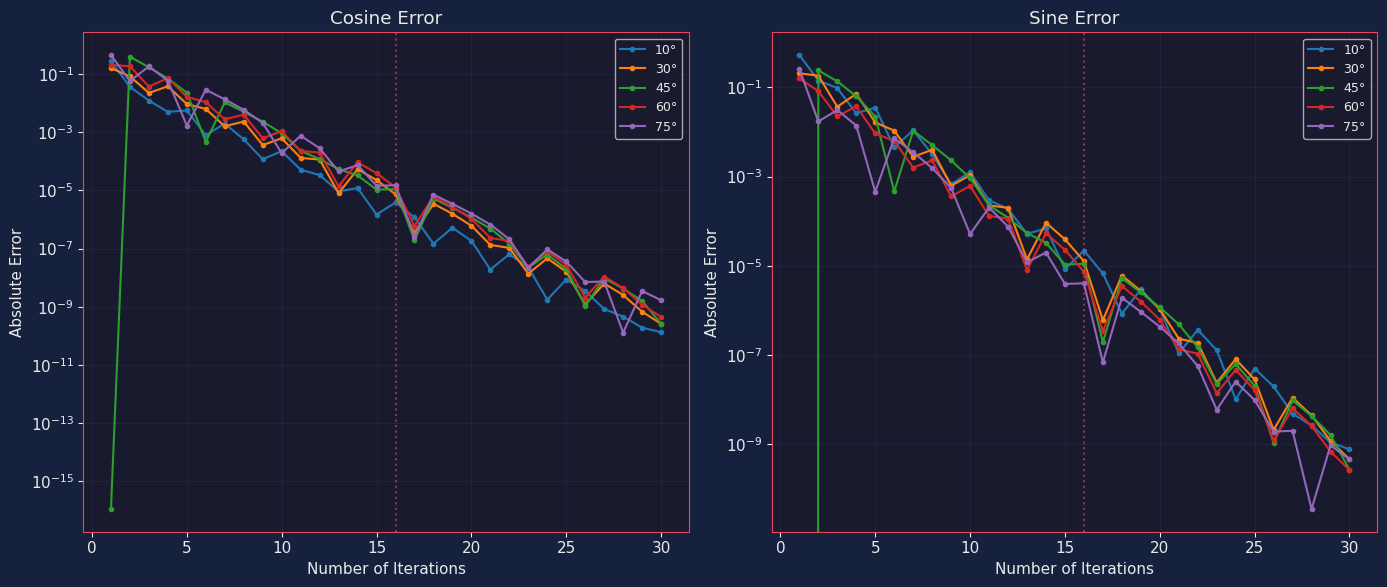

Key takeaway: each additional iteration roughly adds 1 bit of precision.
At 16 iterations, error is approximately 2^-16 ≈ 1.53e-05


In [5]:
test_angles_deg = [10, 30, 45, 60, 75]
max_iters = 30

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

for angle_deg in test_angles_deg:
    angle_rad = math.radians(angle_deg)
    cos_exact = math.cos(angle_rad)
    sin_exact = math.sin(angle_rad)
    
    cos_errors = []
    sin_errors = []
    
    for n in range(1, max_iters + 1):
        K = get_cordic_gain(n)
        x_f, y_f, _ = cordic_circular_rotation(1/K, 0, angle_rad, n)
        cos_errors.append(abs(x_f - cos_exact))
        sin_errors.append(abs(y_f - sin_exact))
    
    iters = list(range(1, max_iters + 1))
    ax1.semilogy(iters, cos_errors, '-o', markersize=3, label=f'{angle_deg}°')
    ax2.semilogy(iters, sin_errors, '-o', markersize=3, label=f'{angle_deg}°')

for ax, title in [(ax1, 'Cosine Error'), (ax2, 'Sine Error')]:
    ax.set_xlabel('Number of Iterations')
    ax.set_ylabel('Absolute Error')
    ax.set_title(title)
    ax.legend(fontsize=9)
    # Mark the 16-iteration line (our RTL config)
    ax.axvline(x=16, color='#e94560', linestyle=':', alpha=0.6, label='RTL (16 iter)')

plt.tight_layout()
plt.show()

print('Key takeaway: each additional iteration roughly adds 1 bit of precision.')
print(f'At 16 iterations, error is approximately 2^-16 ≈ {2**-16:.2e}')

---
## 4. Fixed-Point Arithmetic Emulation

The Verilog RTL uses **16-bit signed integers** (Q1.15), not floating-point. Let's emulate the exact fixed-point behavior and compare it to the floating-point version to understand **quantization error**.

Conventions matching our RTL:
- `inout_width = 16` → Q1.15, where `1.0 = 2^15 = 32768`
- `phase_width = 18` → `π = 2^17 = 131072`
- Arithmetic right shift `>>>` preserves the sign bit

In [6]:
def to_fixed(value, frac_bits):
    """Convert a float to signed fixed-point integer."""
    return int(round(value * (2**frac_bits)))

def from_fixed(value, frac_bits):
    """Convert a signed fixed-point integer back to float."""
    return value / (2**frac_bits)

def arithmetic_right_shift(val, shift, bit_width):
    """Emulate Verilog's >>> for signed values in a given bit width."""
    # Mask to bit_width (simulate 2's complement)
    mask = (1 << bit_width) - 1
    val = val & mask
    # Check sign bit
    if val & (1 << (bit_width - 1)):  # negative
        # Fill with 1s from the top
        val = val | (~mask)
    return val >> shift

def clamp_signed(val, bit_width):
    """Clamp value to signed range of bit_width."""
    max_val = (1 << (bit_width - 1)) - 1
    min_val = -(1 << (bit_width - 1))
    return max(min_val, min(max_val, val))


def cordic_fixed_point(angle_rad, n_iter=16, data_bits=16, phase_bits=18):
    """
    Fixed-point CORDIC matching the Verilog RTL behavior exactly.
    Returns: (cos_float, sin_float, x_raw, y_raw)
    """
    data_frac = data_bits - 1   # Q1.15 → 15 fractional bits
    phase_scale = 2**(phase_bits - 1) / math.pi  # pi = 2^17
    
    # Pre-compute atan LUT in fixed-point
    atan_lut = [round(math.atan(2**-j) * phase_scale) for j in range(n_iter)]
    
    # CORDIC gain
    K = get_cordic_gain(n_iter)
    
    # Initial values: x0 = 1/K, y0 = 0, z0 = angle
    x = to_fixed(1.0 / K, data_frac)
    y = 0
    z = round(angle_rad * phase_scale)
    
    for j in range(n_iter):
        # Decision based on sign of z (MSB)
        if z < 0:  # phase < 0 → rotate CW (state 3'd2 in RTL)
            x_next = x + arithmetic_right_shift(y, j, data_bits)
            y_next = y - arithmetic_right_shift(x, j, data_bits)
            z_next = z + atan_lut[j]
        else:      # phase >= 0 → rotate CCW (state 3'd3 in RTL)
            x_next = x - arithmetic_right_shift(y, j, data_bits)
            y_next = y + arithmetic_right_shift(x, j, data_bits)
            z_next = z - atan_lut[j]
        
        # Clamp to bit width (emulates register overflow)
        x = clamp_signed(x_next, data_bits)
        y = clamp_signed(y_next, data_bits)
        z = clamp_signed(z_next, phase_bits)
    
    cos_val = from_fixed(x, data_frac)
    sin_val = from_fixed(y, data_frac)
    return cos_val, sin_val, x, y


# ── Compare floating-point vs fixed-point CORDIC (with error analysis) ──
header = (f'{"Angle":>8s} | {"cos (float)":>12s} {"cos (fixed)":>12s} {"cos (exact)":>12s} {"Δ fixed-exact":>14s} | '
         f'{"sin (float)":>12s} {"sin (fixed)":>12s} {"sin (exact)":>12s} {"Δ fixed-exact":>14s}')
print(header)
print('-' * len(header))

max_cos_err = 0
max_sin_err = 0

for angle_deg in [10, 30, 45, 60, 90, -30, -45, -60, -90]:
    angle_rad = math.radians(angle_deg)
    K = get_cordic_gain(16)
    
    # Floating-point CORDIC
    xf, yf, _ = cordic_circular_rotation(1/K, 0, angle_rad, 16)
    
    # Fixed-point CORDIC
    cos_fx, sin_fx, _, _ = cordic_fixed_point(angle_rad, n_iter=16)
    
    # Exact
    cos_ex = math.cos(angle_rad)
    sin_ex = math.sin(angle_rad)
    
    # Errors
    cos_err = abs(cos_fx - cos_ex)
    sin_err = abs(sin_fx - sin_ex)
    max_cos_err = max(max_cos_err, cos_err)
    max_sin_err = max(max_sin_err, sin_err)
    
    print(f'{angle_deg:>7d}° | {xf:>12.6f} {cos_fx:>12.6f} {cos_ex:>12.6f} {cos_err:>14.2e} | '
          f'{yf:>12.6f} {sin_fx:>12.6f} {sin_ex:>12.6f} {sin_err:>14.2e}')

print('-' * len(header))
print(f'\nMax |Δcos| = {max_cos_err:.2e}   Max |Δsin| = {max_sin_err:.2e}')
print(f'LSB @ 16-bit Q1.15 = {1/2**15:.2e}  →  error ≈ {max_cos_err / (1/2**15):.1f} LSBs (cos), {max_sin_err / (1/2**15):.1f} LSBs (sin)')


   Angle |  cos (float)  cos (fixed)  cos (exact)  Δ fixed-exact |  sin (float)  sin (fixed)  sin (exact)  Δ fixed-exact
------------------------------------------------------------------------------------------------------------------------
     10° |     0.984804     0.984741     0.984808       6.65e-05 |     0.173670     0.173676     0.173648       2.74e-05
     30° |     0.866018     0.866089     0.866025       6.35e-05 |     0.500013     0.500000     0.500000       5.55e-17
     45° |     0.707096     0.707123     0.707107       1.60e-05 |     0.707118     0.707092     0.707107       1.45e-05
     60° |     0.500013     0.499878     0.500000       1.22e-04 |     0.866018     0.866119     0.866025       9.40e-05
     90° |    -0.000018     0.000092     0.000000       9.16e-05 |     1.000000     0.999969     1.000000       3.05e-05
    -30° |     0.866018     0.866058     0.866025       3.29e-05 |    -0.500013    -0.499908    -0.500000       9.16e-05
    -45° |     0.707118     0.70

---
## 5. Quantization Error: Fixed-Point vs Floating-Point

For every angle from 1° to 89°, let's compare the cosine error from both the floating-point and the fixed-point CORDIC. The gap between the two curves shows the **quantization noise floor** introduced by the 16-bit word width.

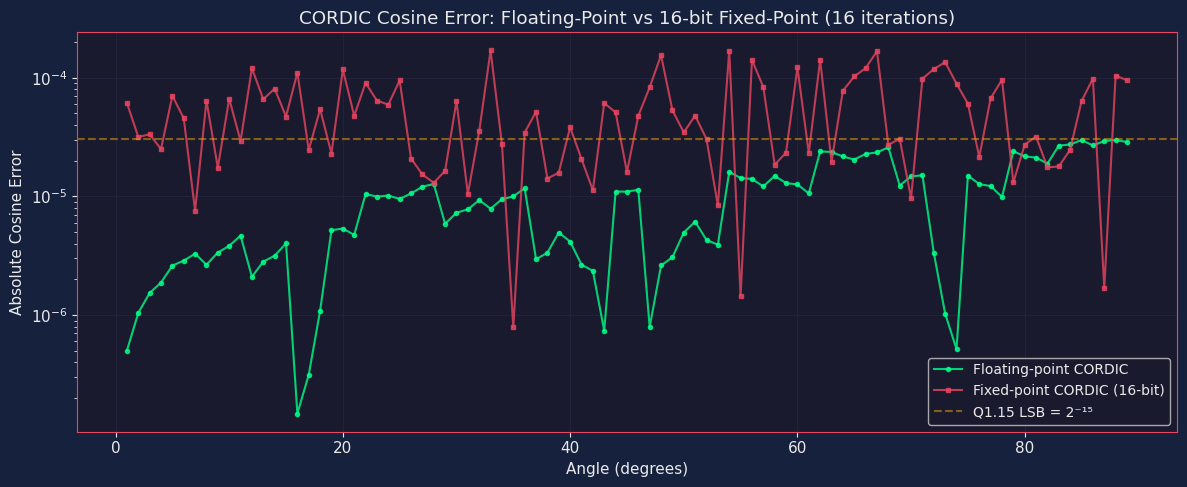

In [7]:
angles_deg = np.arange(1, 90, 1)
float_errors = []
fixed_errors = []
K = get_cordic_gain(16)

for a in angles_deg:
    a_rad = math.radians(a)
    cos_exact = math.cos(a_rad)
    
    # Float CORDIC
    xf, _, _ = cordic_circular_rotation(1/K, 0, a_rad, 16)
    float_errors.append(abs(xf - cos_exact))
    
    # Fixed CORDIC
    cos_fx, _, _, _ = cordic_fixed_point(a_rad, 16)
    fixed_errors.append(abs(cos_fx - cos_exact))

fig, ax = plt.subplots(figsize=(12, 5))
ax.semilogy(angles_deg, float_errors, 'o-', markersize=3, color='#00ff88', 
            label='Floating-point CORDIC', alpha=0.8)
ax.semilogy(angles_deg, fixed_errors, 's-', markersize=3, color='#e94560',
            label='Fixed-point CORDIC (16-bit)', alpha=0.8)
ax.axhline(y=2**-15, color='#f0a500', linestyle='--', alpha=0.5, label='Q1.15 LSB = 2⁻¹⁵')
ax.set_xlabel('Angle (degrees)')
ax.set_ylabel('Absolute Cosine Error')
ax.set_title('CORDIC Cosine Error: Floating-Point vs 16-bit Fixed-Point (16 iterations)')
ax.legend(fontsize=10)
plt.tight_layout()
plt.show()

---
## 6. The Atan Look-Up Table

The entire "intelligence" of CORDIC is encoded in a small LUT of pre-computed angles $\alpha_j = \arctan(2^{-j})$. Let's visualize it and understand why the angles form a complete basis.

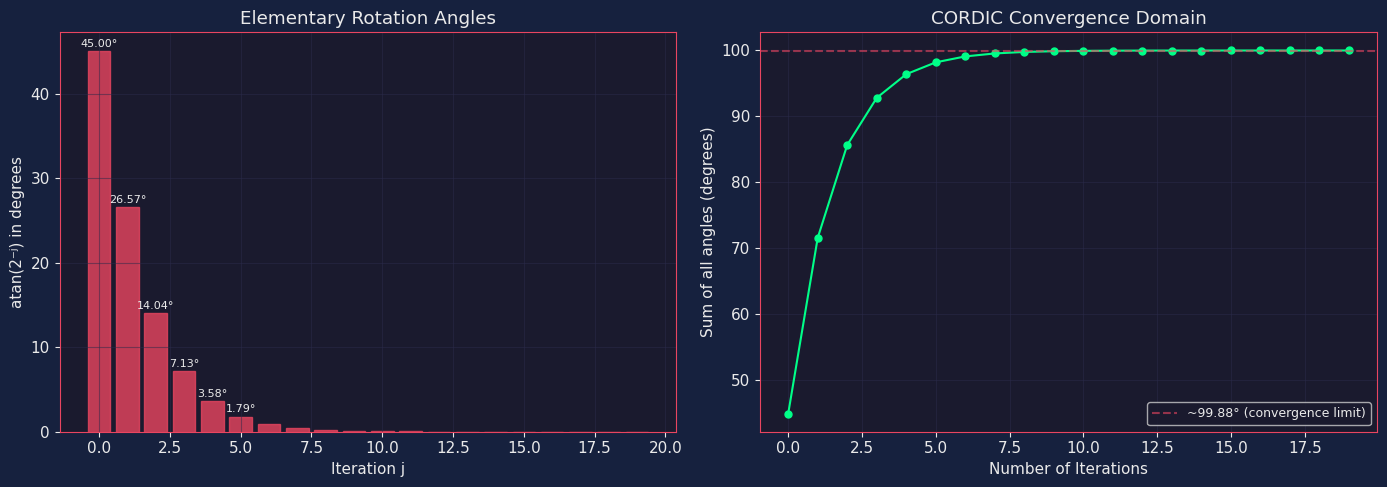

Sum of 20 angles = 99.8829° — this is the maximum angle CORDIC can reach.
For angles beyond this, pre-rotation by ±90° or ±180° is needed.


In [8]:
n = 20
atan_angles = [math.degrees(math.atan(2**-j)) for j in range(n)]
cumsum = np.cumsum(atan_angles)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Individual angles
bars = ax1.bar(range(n), atan_angles, color='#e94560', alpha=0.8, edgecolor='#e94560')
ax1.set_xlabel('Iteration j')
ax1.set_ylabel('atan(2⁻ʲ) in degrees')
ax1.set_title('Elementary Rotation Angles')
for i, v in enumerate(atan_angles[:6]):
    ax1.text(i, v + 0.5, f'{v:.2f}°', ha='center', fontsize=8, color='#eaeaea')

# Cumulative sum — shows convergence domain
ax2.plot(range(n), cumsum, 'o-', color='#00ff88', markersize=5)
ax2.axhline(y=99.88, color='#e94560', linestyle='--', alpha=0.6, label='~99.88° (convergence limit)')
ax2.set_xlabel('Number of Iterations')
ax2.set_ylabel('Sum of all angles (degrees)')
ax2.set_title('CORDIC Convergence Domain')
ax2.legend(fontsize=9)

plt.tight_layout()
plt.show()

print(f'Sum of {n} angles = {cumsum[-1]:.4f}° — this is the maximum angle CORDIC can reach.')
print(f'For angles beyond this, pre-rotation by ±90° or ±180° is needed.')

---
## 7. The CORDIC Gain Factor K

Each micro-rotation actually **stretches** the vector by a factor of $\sqrt{1 + 2^{-2j}}$. The total gain $K$ is the product of all these factors. It converges very quickly to ~1.6468.

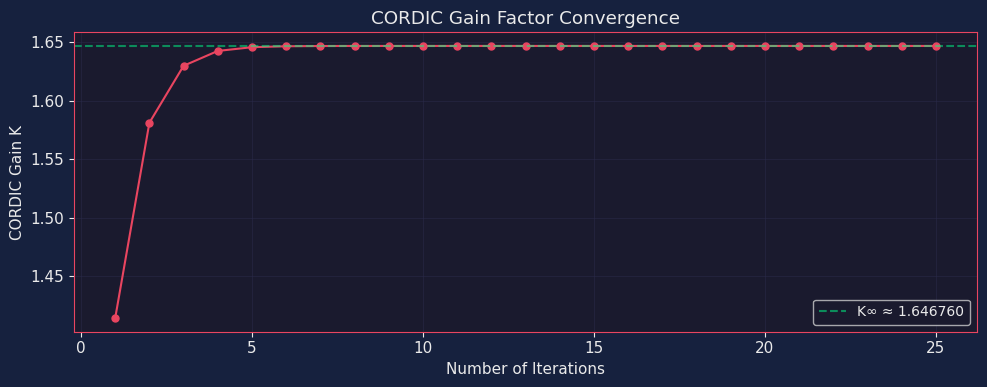

K converges to 1.6467602581
1/K = 0.6072529350

In the RTL, we pre-multiply x0 by 1/K so the output is directly cos/sin.
Alternatively, a post-multiplier can compensate after the iterations.


In [9]:
max_n = 25
K_values = []
K = 1.0
for j in range(max_n):
    K *= math.sqrt(1 + 2**(-2*j))
    K_values.append(K)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(range(1, max_n+1), K_values, 'o-', color='#e94560', markersize=5)
ax.axhline(y=K_values[-1], color='#00ff88', linestyle='--', alpha=0.5,
           label=f'K∞ ≈ {K_values[-1]:.6f}')
ax.set_xlabel('Number of Iterations')
ax.set_ylabel('CORDIC Gain K')
ax.set_title('CORDIC Gain Factor Convergence')
ax.legend(fontsize=10)
plt.tight_layout()
plt.show()

print(f'K converges to {K_values[-1]:.10f}')
print(f'1/K = {1/K_values[-1]:.10f}')
print(f'\nIn the RTL, we pre-multiply x0 by 1/K so the output is directly cos/sin.')
print(f'Alternatively, a post-multiplier can compensate after the iterations.')

---
## 8. Hyperbolic CORDIC — Square Root

By switching to **hyperbolic coordinates** ($m = -1$) and **vectoring mode** (drive $y \to 0$), CORDIC can compute $\sqrt{a}$.

Setup:
- $x_0 = a + 0.25$, $y_0 = a - 0.25$, $z_0 = 0$
- After convergence: $x_n = K_{hyp} \cdot \sqrt{a}$
- Iterations start at $j=1$ (not 0)
- Iterations $j = 4, 13, 40, ...$ must be **repeated** for convergence

In [10]:
def cordic_hyperbolic_vectoring(x0, y0, z0, n_iter=15, reps=None):
    """
    Hyperbolic CORDIC — Vectoring Mode.
    Drives y toward 0. Used for sqrt.
    
    Key differences from circular:
      - Uses atanh(2^-j) instead of atan(2^-j)
      - x equation sign flips (m = -1)
      - Starts at j=1, not j=0
      - Requires repeated iterations for convergence
    """
    if reps is None:
        reps = [4, 13]  # Standard repetitions
    
    # Build iteration sequence
    iters = list(range(1, n_iter + 1))
    iters.extend(reps)
    iters.sort()
    
    # atanh LUT
    atanh_lut = {j: math.atanh(2**-j) for j in range(1, n_iter + 1)}
    
    x, y, z = x0, y0, z0
    history = [(x, y, z)]
    
    for j in iters:
        # Vectoring: decision based on sign of y
        sigma = -1 if y >= 0 else 1
        
        # Hyperbolic equations (note: x uses + instead of - for m=-1)
        x_next = x + sigma * y * (2**-j)   # <-- "+" for hyperbolic
        y_next = y + sigma * x * (2**-j)
        z_next = z - sigma * atanh_lut[j]
        
        x, y, z = x_next, y_next, z_next
        history.append((x, y, z))
    
    return x, y, z, history


def get_hyperbolic_gain(n_iter=15, reps=None):
    """Compute hyperbolic CORDIC gain K_hyp."""
    if reps is None:
        reps = [4, 13]
    iters = list(range(1, n_iter + 1))
    iters.extend(reps)
    iters.sort()
    K = 1.0
    for j in iters:
        K *= math.sqrt(1 - 2**(-2*j))
    return K


# Test sqrt computation
K_hyp = get_hyperbolic_gain(15)
print(f'Hyperbolic K = {K_hyp:.6f}')
print(f'1/K_hyp = {1/K_hyp:.6f}')
print()

test_values = [0.25, 0.5, 1.0, 1.69, 2.0]
print(f'{"a":>6s} | {"x0":>8s} {"y0":>8s} | {"x_n (raw)":>10s} {"sqrt (CORDIC)":>14s} {"sqrt (exact)":>14s} | {"Error":>10s}')
print('-' * 85)

for a in test_values:
    x0 = a + 0.25
    y0 = a - 0.25
    z0 = 0.0
    
    x_n, y_n, z_n, _ = cordic_hyperbolic_vectoring(x0, y0, z0, n_iter=15)
    sqrt_cordic = x_n / K_hyp
    sqrt_exact = math.sqrt(a)
    error = abs(sqrt_cordic - sqrt_exact)
    
    print(f'{a:>6.2f} | {x0:>8.4f} {y0:>8.4f} | {x_n:>10.6f} {sqrt_cordic:>14.8f} {sqrt_exact:>14.8f} | {error:>10.2e}')

Hyperbolic K = 0.828159
1/K_hyp = 1.207497

     a |       x0       y0 |  x_n (raw)  sqrt (CORDIC)   sqrt (exact) |      Error
-------------------------------------------------------------------------------------
  0.25 |   0.5000   0.0000 |   0.414080     0.50000000     0.50000000 |   4.62e-13
  0.50 |   0.7500   0.2500 |   0.585597     0.70710678     0.70710678 |   1.42e-10
  1.00 |   1.2500   0.7500 |   0.828159     1.00000000     1.00000000 |   3.25e-11
  1.69 |   1.9400   1.4400 |   1.076607     1.30000000     1.30000000 |   6.80e-11
  2.00 |   2.2500   1.7500 |   1.171194     1.41421356     1.41421356 |   6.00e-10


---
## 9. Visualizing Hyperbolic CORDIC Convergence

In vectoring mode, the y-component is driven toward zero. Let's trace how $y$ converges for different input values.

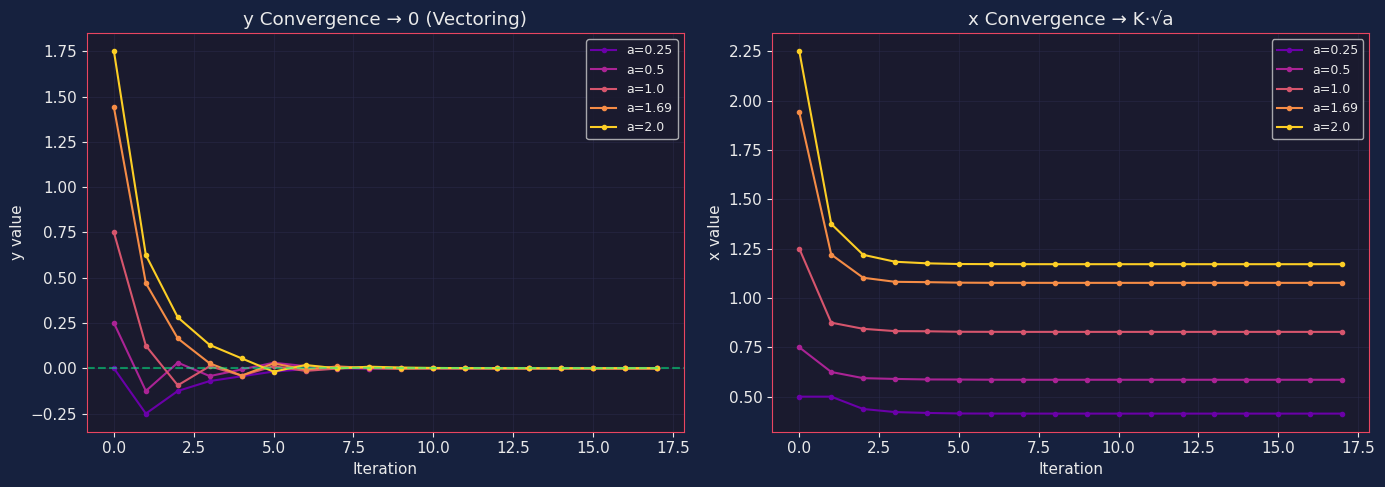

In [11]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

colors_map = plt.cm.plasma(np.linspace(0.2, 0.9, len(test_values)))

for idx, a in enumerate(test_values):
    x0 = a + 0.25
    y0 = a - 0.25
    _, _, _, history = cordic_hyperbolic_vectoring(x0, y0, 0.0, n_iter=15)
    
    ys = [h[1] for h in history]
    xs = [h[0] for h in history]
    iters = range(len(ys))
    
    ax1.plot(iters, ys, 'o-', markersize=3, color=colors_map[idx], label=f'a={a}')
    ax2.plot(iters, xs, 'o-', markersize=3, color=colors_map[idx], label=f'a={a}')

ax1.axhline(y=0, color='#00ff88', linestyle='--', alpha=0.5)
ax1.set_xlabel('Iteration')
ax1.set_ylabel('y value')
ax1.set_title('y Convergence → 0 (Vectoring)')
ax1.legend(fontsize=9)

ax2.set_xlabel('Iteration')
ax2.set_ylabel('x value')
ax2.set_title('x Convergence → K·√a')
ax2.legend(fontsize=9)

plt.tight_layout()
plt.show()

---
## 10. Summary: CORDIC Function Modes

| Coordinate | Mode | Inputs | Output | Function |
|:-----------|:-----|:-------|:-------|:---------|
| Circular (m=1) | Rotation | x₀=1/K, y₀=0, z₀=θ | x→cos(θ), y→sin(θ) | **Trig** |
| Circular (m=1) | Vectoring | x₀, y₀, z₀=0 | x→√(x²+y²), z→atan(y/x) | **Magnitude & Phase** |
| Linear (m=0) | Rotation | x₀=a, y₀=0, z₀=b | y→a·b | **Multiply** |
| Linear (m=0) | Vectoring | x₀=a, y₀=b, z₀=0 | z→b/a | **Divide** |
| Hyperbolic (m=−1) | Rotation | x₀=1/K, y₀=0, z₀=θ | x→cosh(θ), y→sinh(θ) | **Hyperbolic Trig** |
| Hyperbolic (m=−1) | Vectoring | x₀=a+¼, y₀=a−¼, z₀=0 | x→K·√a | **Square Root** |